In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    device = torch.device("cuda")
else:
    print("Running on CPU")
    device = torch.device("cpu")

print("Selected device:", device)

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
Selected device: cuda


In [ ]:
# Find the uploaded Excel workbook automatically

import os

excel_files = [
    f for f in os.listdir("/content")
    if f.lower().endswith((".xlsx", ".xls"))
]

print("Excel files found:")
for f in excel_files:
    print("-", f)

Excel files found:
- Boom_by_Booms_PrePyTorch_Complete_v10_SpaceCollab.xlsx


In [ ]:
# Open the master workbook and inspect its sheets

import pandas as pd

file_path = "/content/Boom_by_Booms_PrePyTorch_Complete_v10_SpaceCollab.xlsx"

xls = pd.ExcelFile(file_path)

print("Number of sheets:", len(xls.sheet_names))
print("\nSheet names:\n")

for i, sheet in enumerate(xls.sheet_names, start=1):
    print(f"{i:02d}. {sheet}")

Number of sheets: 49

Sheet names:

01. START_HERE
02. DPSU_VoP_2013_17
03. DPSU_PAT_2013_17
04. DPSU_VoP_2014_18
05. DPSU_PAT_2014_18
06. DPSU_VoP_2015_19
07. DPSU_PAT_2015_19
08. DPSU_VoP_2016_20
09. DPSU_PAT_2016_20
10. DPSU_VoP_2017_21
11. DPSU_PAT_2017_21
12. DPSU_VoP_2018_22
13. DPSU_PAT_2018_22
14. Defence_Exports
15. Sector_Production
16. README
17. MASTER_DPSU
18. MASTER DEFENCE ANNUAL
19. AUDIT STATUS
20. AUDIT NOTES
21. CONFLICT REVIEW
22. RECONCILIATION NOTES
23. DPSU_ANALYTICAL
24. LAYER2_DEFENCE_ANNUAL
25. LAYER2_DEFENCE_QUARTERLY
26. LAYER2_SOURCE_NOTES
27. LAYER2_EXPORTS
28. LAYER2_QA
29. LAYER3_DATA
30. LAYER3_METHOD
31. LAYER4_NSIL_FIN
32. LAYER4_SOURCE_AUDIT
33. LAYER4_NSIL_LAUNCH
34. LAYER4_NSIL_VEHICLE
35. LAYER4_NSIL_CONTEXT
36. LAYER4_METHOD
37. MASTER_ANALYTICAL
38. VARIABLE_DICTIONARY
39. DESCRIPTIVE_STATS
40. HYPOTHESIS
41. AUDIT_REGISTER
42. GRAPH_DATA
43. ANALYSIS_GRAPHS
44. PYTORCH_GATE
45. PROJECT_STATUS
46. SPACE_PRIVATE_GOVT_COLLAB
47. SPACE_PRIVATE_GOVT

In [ ]:
# ============================================================
# Inspect the analytical/model-readiness sheets
# ============================================================

sheets_to_inspect = [
    "MASTER_ANALYTICAL",
    "MASTER_DEFENCE_ANNUAL",
    "DPSU_ANALYTICAL",
    "LAYER4_NSIL_FIN",
    "PYTORCH_GATE",
    "SPACE_PRIVATE_GOVT_COLLAB"
]

for sheet in sheets_to_inspect:
    print("\n" + "=" * 80)
    print(f"SHEET: {sheet}")
    print("=" * 80)

    temp = pd.read_excel(file_path, sheet_name=sheet)

    print("Shape:", temp.shape)
    print("Columns:")
    print(temp.columns.tolist())

    print("\nFirst 5 rows:")
    display(temp.head())


SHEET: MASTER_ANALYTICAL
Shape: (9, 19)
Columns:
['FY', 'Total Defence Production (₹ crore)', 'Private Production (₹ crore)', 'Private Share (%)', 'Defence Exports (₹ crore)', 'DPSU Production (₹ crore)', 'New DPSU/OFB (₹ crore)', 'Non-DPSU (₹ crore)', 'NSIL Total Revenue (₹ lakh)', 'NSIL PAT (₹ lakh)', 'DRDO LAToT (annual)', 'Indigenised Items (reporting-year)', 'Data Status', 'Analytical Use', 'Source / Provenance', 'Notes', 'Private Space Collaboration Events', 'Private Space Collaboration Financial Assistance (₹ crore)', 'Space Collaboration Treatment']

First 5 rows:


,FY,Total Defence Production (₹ crore),Private Production (₹ crore),Private Share (%),Defence Exports (₹ crore),DPSU Production (₹ crore),New DPSU/OFB (₹ crore),Non-DPSU (₹ crore),NSIL Total Revenue (₹ lakh),NSIL PAT (₹ lakh),DRDO LAToT (annual),Indigenised Items (reporting-year),Data Status,Analytical Use,Source / Provenance,Notes,Private Space Collaboration Events,Private Space Collaboration Financial Assistance (₹ crore),Space Collaboration Treatment
0,2016-17,NaN,NaN,NaN,1522,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Annual,exports,LAYER2/LAYER3,NaN,NaN,NaN,Context/event evidence; not a causal regressor.
1,2017-18,NaN,NaN,NaN,4682,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Annual,exports,LAYER2/LAYER3,NaN,NaN,NaN,Context/event evidence; not a causal regressor.
2,2018-19,NaN,NaN,NaN,10746,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Annual,exports,LAYER2/LAYER3,NaN,NaN,NaN,Context/event evidence; not a causal regressor.
3,2019-20,79071.0,15894.0,20.100922,9116,46755.0,9227.0,6295.0,32159.14,5129.45,NaN,NaN,Annual,defence production; private participation; exp...,PDF p.9,NaN,NaN,NaN,Context/event evidence; not a causal regressor.
4,2020-21,84643.0,17268.0,20.400978,8435,46711.0,14635.0,6029.0,52571.08,15889.54,182.0,NaN,Annual,defence production; private participation; exp...,PDF p.10,NaN,1.0,NaN,Context/event evidence; not a causal regressor.



SHEET: MASTER_DEFENCE_ANNUAL


ValueError: Worksheet named 'MASTER_DEFENCE_ANNUAL' not found

In [ ]:
# Check the exact sheet names stored in the workbook

for i, sheet in enumerate(xls.sheet_names):
    if "MASTER" in sheet.upper() or "PYTORCH" in sheet.upper() or "NSIL" in sheet.upper():
        print(i, repr(sheet))

16 'MASTER_DPSU'
17 'MASTER DEFENCE ANNUAL'
30 'LAYER4_NSIL_FIN'
32 'LAYER4_NSIL_LAUNCH'
33 'LAYER4_NSIL_VEHICLE'
34 'LAYER4_NSIL_CONTEXT'
36 'MASTER_ANALYTICAL'
43 'PYTORCH_GATE'


In [ ]:
# Find the exact stored representation and Unicode characters
for i, s in enumerate(xls.sheet_names):
    if "DEFENCE" in s.upper():
        print("Index:", i)
        print("repr:", repr(s))
        print("Characters:")
        for j, ch in enumerate(s):
            print(j, repr(ch), ord(ch))

Index: 13
repr: 'Defence_Exports'
Characters:
0 'D' 68
1 'e' 101
2 'f' 102
3 'e' 101
4 'n' 110
5 'c' 99
6 'e' 101
7 '_' 95
8 'E' 69
9 'x' 120
10 'p' 112
11 'o' 111
12 'r' 114
13 't' 116
14 's' 115
Index: 17
repr: 'MASTER DEFENCE ANNUAL'
Characters:
0 'M' 77
1 'A' 65
2 'S' 83
3 'T' 84
4 'E' 69
5 'R' 82
6 ' ' 32
7 'D' 68
8 'E' 69
9 'F' 70
10 'E' 69
11 'N' 78
12 'C' 67
13 'E' 69
14 ' ' 32
15 'A' 65
16 'N' 78
17 'N' 78
18 'U' 85
19 'A' 65
20 'L' 76
Index: 23
repr: 'LAYER2_DEFENCE_ANNUAL'
Characters:
0 'L' 76
1 'A' 65
2 'Y' 89
3 'E' 69
4 'R' 82
5 '2' 50
6 '_' 95
7 'D' 68
8 'E' 69
9 'F' 70
10 'E' 69
11 'N' 78
12 'C' 67
13 'E' 69
14 '_' 95
15 'A' 65
16 'N' 78
17 'N' 78
18 'U' 85
19 'A' 65
20 'L' 76
Index: 24
repr: 'LAYER2_DEFENCE_QUARTERLY'
Characters:
0 'L' 76
1 'A' 65
2 'Y' 89
3 'E' 69
4 'R' 82
5 '2' 50
6 '_' 95
7 'D' 68
8 'E' 69
9 'F' 70
10 'E' 69
11 'N' 78
12 'C' 67
13 'E' 69
14 '_' 95
15 'Q' 81
16 'U' 85
17 'A' 65
18 'R' 82
19 'T' 84
20 'E' 69
21 'R' 82
22 'L' 76
23 'Y' 89


In [ ]:
# Load the correct sheet using its actual name

df_test = xls.parse("MASTER DEFENCE ANNUAL")

print("SUCCESS")
print("Shape:", df_test.shape)
print("Columns:")
print(df_test.columns.tolist())

display(df_test.head())

SUCCESS
Shape: (15, 9)
Columns:
['FY', 'Total Defence Production (₹ crore)', 'Public/DPSU Production (₹ crore)', 'Private Production (₹ crore)', 'Private Share (%)', 'Defence Exports (₹ crore)', 'Status', 'Source Sheet(s)', 'Notes']


,FY,Total Defence Production (₹ crore),Public/DPSU Production (₹ crore),Private Production (₹ crore),Private Share (%),Defence Exports (₹ crore),Status,Source Sheet(s),Notes
0,2019-20,79071.0,62277.00,15894.0,20.100922,9116.0,NaN,Sector_Production; Defence_Exports,NaN
1,2020-21,84643.0,67375.00,17268.0,20.400978,8435.0,NaN,Sector_Production; Defence_Exports,NaN
2,2021-22,94845.0,74925.00,19920.0,21.002689,12815.0,NaN,Sector_Production; Defence_Exports,NaN
3,2022-23,108684.0,87601.00,21083.0,19.398440,15920.0,NaN,Sector_Production; Defence_Exports,NaN
4,2023-24 Q1,20558.0,15922.18,4636.0,22.550832,NaN,Partial/provisional,Sector_Production,Retain as raw observation; not a full-year com...


In [ ]:
# Inspect the exact annual series we may use for the forecasting baseline

annual = xls.parse("MASTER DEFENCE ANNUAL")

print("ANNUAL DEFENCE DATA")
print("=" * 70)

display(
    annual[
        [
            "FY",
            "Total Defence Production (₹ crore)",
            "Private Production (₹ crore)",
            "Private Share (%)",
            "Defence Exports (₹ crore)",
            "Status",
            "Notes"
        ]
    ]
)

ANNUAL DEFENCE DATA


,FY,Total Defence Production (₹ crore),Private Production (₹ crore),Private Share (%),Defence Exports (₹ crore),Status,Notes
0,2019-20,79071.0,15894.0,20.100922,9116.0,NaN,NaN
1,2020-21,84643.0,17268.0,20.400978,8435.0,NaN,NaN
2,2021-22,94845.0,19920.0,21.002689,12815.0,NaN,NaN
3,2022-23,108684.0,21083.0,19.398440,15920.0,NaN,NaN
4,2023-24 Q1,20558.0,4636.0,22.550832,NaN,Partial/provisional,Retain as raw observation; not a full-year com...
5,2023-24 Q2,26706.0,5806.0,21.740433,NaN,Partial/provisional,Retain as raw observation; not a full-year com...
6,2023-24 Q3,30017.0,6490.0,21.621081,NaN,Partial/provisional,Retain as raw observation; not a full-year com...
7,2024-25 Q1,25229.0,6080.0,24.099251,NaN,Partial/provisional,Retain as raw observation; not a full-year com...
8,2024-25 Q2,31970.0,7496.0,23.446982,NaN,Partial/provisional,Retain as raw observation; not a full-year com...
9,2024-25 Q3 (Provisional),32502.0,7532.0,23.173959,NaN,Partial/provisional,Retain as raw observation; not a full-year com...


In [ ]:
# Identify the clean observations available for forecasting

annual = xls.parse("MASTER DEFENCE ANNUAL")

print("CANDIDATE FORECASTING SERIES")
print("=" * 70)

# 1. Annual defence production
production = annual[
    annual["Total Defence Production (₹ crore)"].notna()
][[
    "FY",
    "Total Defence Production (₹ crore)",
    "Status"
]].copy()

print("\n1. TOTAL DEFENCE PRODUCTION")
display(production)

# 2. Annual defence exports
exports = annual[
    annual["Defence Exports (₹ crore)"].notna()
][[
    "FY",
    "Defence Exports (₹ crore)",
    "Status"
]].copy()

print("\n2. DEFENCE EXPORTS")
display(exports)

print("\nObservation counts:")
print("Production observations:", len(production))
print("Export observations:", len(exports))

CANDIDATE FORECASTING SERIES

1. TOTAL DEFENCE PRODUCTION


,FY,Total Defence Production (₹ crore),Status
0,2019-20,79071.0,NaN
1,2020-21,84643.0,NaN
2,2021-22,94845.0,NaN
3,2022-23,108684.0,NaN
4,2023-24 Q1,20558.0,Partial/provisional
5,2023-24 Q2,26706.0,Partial/provisional
6,2023-24 Q3,30017.0,Partial/provisional
7,2024-25 Q1,25229.0,Partial/provisional
8,2024-25 Q2,31970.0,Partial/provisional
9,2024-25 Q3 (Provisional),32502.0,Partial/provisional



2. DEFENCE EXPORTS


,FY,Defence Exports (₹ crore),Status
0,2019-20,9116.0,NaN
1,2020-21,8435.0,NaN
2,2021-22,12815.0,NaN
3,2022-23,15920.0,NaN
10,2016-17,1522.0,Export only
11,2017-18,4682.0,Export only
12,2018-19,10746.0,Export only
13,2023-24,21083.0,Export only
14,2024-25,23622.0,Export only



Observation counts:
Production observations: 10
Export observations: 9


In [ ]:
# Build the clean annual defence-export forecasting series

exports_ts = annual[
    annual["Defence Exports (₹ crore)"].notna()
][[
    "FY",
    "Defence Exports (₹ crore)"
]].copy()

# Sort chronologically
exports_ts = exports_ts.sort_values("FY").reset_index(drop=True)

print("CLEAN DEFENCE EXPORT TIME SERIES")
print("=" * 60)

display(exports_ts)

print("\nNumber of annual observations:", len(exports_ts))
print("Missing values:", exports_ts["Defence Exports (₹ crore)"].isna().sum())

CLEAN DEFENCE EXPORT TIME SERIES


,FY,Defence Exports (₹ crore)
0,2016-17,1522.0
1,2017-18,4682.0
2,2018-19,10746.0
3,2019-20,9116.0
4,2020-21,8435.0
5,2021-22,12815.0
6,2022-23,15920.0
7,2023-24,21083.0
8,2024-25,23622.0



Number of annual observations: 9
Missing values: 0


In [ ]:
# Create a naive last-value forecasting baseline

baseline = exports_ts.copy()

value_col = "Defence Exports (₹ crore)"

# Prediction for each year = actual value from the previous year
baseline["Naive Prediction (₹ crore)"] = baseline[value_col].shift(1)

# Forecast error
baseline["Error (₹ crore)"] = (
    baseline[value_col] - baseline["Naive Prediction (₹ crore)"]
)

# Absolute error
baseline["Absolute Error (₹ crore)"] = baseline["Error (₹ crore)"].abs()

print("NAÏVE BASELINE")
print("=" * 70)

display(baseline)

print("\nFirst observation has no prediction because there is no previous year.")

NAÏVE BASELINE


,FY,Defence Exports (₹ crore),Naive Prediction (₹ crore),Error (₹ crore),Absolute Error (₹ crore)
0,2016-17,1522.0,NaN,NaN,NaN
1,2017-18,4682.0,1522.0,3160.0,3160.0
2,2018-19,10746.0,4682.0,6064.0,6064.0
3,2019-20,9116.0,10746.0,-1630.0,1630.0
4,2020-21,8435.0,9116.0,-681.0,681.0
5,2021-22,12815.0,8435.0,4380.0,4380.0
6,2022-23,15920.0,12815.0,3105.0,3105.0
7,2023-24,21083.0,15920.0,5163.0,5163.0
8,2024-25,23622.0,21083.0,2539.0,2539.0



First observation has no prediction because there is no previous year.


In [ ]:
import numpy as np

# Ignore the first row because it has no prediction
evaluation = baseline.dropna(
    subset=["Naive Prediction (₹ crore)"]
).copy()

# Mean Absolute Error
mae = evaluation["Absolute Error (₹ crore)"].mean()

# Root Mean Squared Error
rmse = np.sqrt(
    (evaluation["Error (₹ crore)"] ** 2).mean()
)

print("NAÏVE BASELINE PERFORMANCE")
print("=" * 60)
print(f"MAE  : ₹{mae:,.2f} crore")
print(f"RMSE : ₹{rmse:,.2f} crore")

print("\nNumber of evaluated forecasts:", len(evaluation))

NAÏVE BASELINE PERFORMANCE
MAE  : ₹3,340.25 crore
RMSE : ₹3,738.43 crore

Number of evaluated forecasts: 8


In [ ]:
# Chronological train/test split for forecasting

train_ts = exports_ts.iloc[:6].copy()
test_ts = exports_ts.iloc[6:].copy()

print("TRAINING PERIOD")
print("=" * 50)
display(train_ts)

print("\nTEST PERIOD")
print("=" * 50)
display(test_ts)

print("\nObservation counts:")
print("Training:", len(train_ts))
print("Test:", len(test_ts))

TRAINING PERIOD


,FY,Defence Exports (₹ crore)
0,2016-17,1522.0
1,2017-18,4682.0
2,2018-19,10746.0
3,2019-20,9116.0
4,2020-21,8435.0
5,2021-22,12815.0



TEST PERIOD


,FY,Defence Exports (₹ crore)
6,2022-23,15920.0
7,2023-24,21083.0
8,2024-25,23622.0



Observation counts:
Training: 6
Test: 3


In [ ]:
# Naïve baseline evaluated only on the held-out test period

test_baseline = test_ts.copy()

value_col = "Defence Exports (₹ crore)"

# First test prediction uses the final training observation
last_train_value = train_ts[value_col].iloc[-1]

predictions = []

for i in range(len(test_baseline)):
    if i == 0:
        # 2022-23 predicted using 2021-22
        predictions.append(last_train_value)
    else:
        # Each subsequent prediction uses the previous actual observation
        predictions.append(test_baseline[value_col].iloc[i - 1])

test_baseline["Naive Prediction (₹ crore)"] = predictions

test_baseline["Error (₹ crore)"] = (
    test_baseline[value_col]
    - test_baseline["Naive Prediction (₹ crore)"]
)

test_baseline["Absolute Error (₹ crore)"] = (
    test_baseline["Error (₹ crore)"].abs()
)

print("HELD-OUT NAÏVE BASELINE")
print("=" * 70)

display(test_baseline)

HELD-OUT NAÏVE BASELINE


,FY,Defence Exports (₹ crore),Naive Prediction (₹ crore),Error (₹ crore),Absolute Error (₹ crore)
6,2022-23,15920.0,12815.0,3105.0,3105.0
7,2023-24,21083.0,15920.0,5163.0,5163.0
8,2024-25,23622.0,21083.0,2539.0,2539.0


In [ ]:
# Final held-out naïve baseline metrics

test_mae = test_baseline["Absolute Error (₹ crore)"].mean()

test_rmse = np.sqrt(
    (test_baseline["Error (₹ crore)"] ** 2).mean()
)

print("HELD-OUT NAÏVE BASELINE PERFORMANCE")
print("=" * 60)
print(f"Test MAE  : ₹{test_mae:,.2f} crore")
print(f"Test RMSE : ₹{test_rmse:,.2f} crore")
print(f"Test observations: {len(test_baseline)}")

HELD-OUT NAÏVE BASELINE PERFORMANCE
Test MAE  : ₹3,602.33 crore
Test RMSE : ₹3,774.66 crore
Test observations: 3


In [ ]:
# Convert the training time series into supervised learning windows

import numpy as np
import torch

values = train_ts["Defence Exports (₹ crore)"].to_numpy(dtype=np.float32)

lookback = 2

X_train = []
y_train = []

for i in range(len(values) - lookback):
    X_train.append(values[i:i + lookback])
    y_train.append(values[i + lookback])

X_train = np.array(X_train, dtype=np.float32)
y_train = np.array(y_train, dtype=np.float32)

print("TRAINING WINDOWS")
print("=" * 60)

for i in range(len(X_train)):
    print(
        f"Input: {X_train[i].tolist()}  "
        f"-> Target: {y_train[i]}"
    )

print("\nShapes before converting to tensors:")
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

TRAINING WINDOWS
Input: [1522.0, 4682.0]  -> Target: 10746.0
Input: [4682.0, 10746.0]  -> Target: 9116.0
Input: [10746.0, 9116.0]  -> Target: 8435.0
Input: [9116.0, 8435.0]  -> Target: 12815.0

Shapes before converting to tensors:
X_train: (4, 2)
y_train: (4,)


In [ ]:
# Convert training windows into PyTorch tensors

X_tensor = torch.tensor(X_train, dtype=torch.float32)
y_tensor = torch.tensor(y_train, dtype=torch.float32)

print("PYTORCH TENSORS")
print("=" * 60)

print("X_tensor:")
print(X_tensor)

print("\nY_tensor:")
print(y_tensor)

print("\nShapes:")
print("X_tensor:", X_tensor.shape)
print("y_tensor:", y_tensor.shape)

print("\nDtypes:")
print("X_tensor:", X_tensor.dtype)
print("y_tensor:", y_tensor.dtype)

print("\nDevice currently:")
print(X_tensor.device)

PYTORCH TENSORS
X_tensor:
tensor([[ 1522.,  4682.],
        [ 4682., 10746.],
        [10746.,  9116.],
        [ 9116.,  8435.]])

Y_tensor:
tensor([10746.,  9116.,  8435., 12815.])

Shapes:
X_tensor: torch.Size([4, 2])
y_tensor: torch.Size([4])

Dtypes:
X_tensor: torch.float32
y_tensor: torch.float32

Device currently:
cpu


In [ ]:
# Establish a reproducible random seed for the experiment

import random

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

print("RANDOM SEED PHASE")
print("=" * 60)
print("Seed:", SEED)
print("PyTorch initial seed:", torch.initial_seed())
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("CUDA device:", torch.cuda.get_device_name(0))

RANDOM SEED PHASE
Seed: 42
PyTorch initial seed: 42
CUDA available: True
CUDA device: Tesla T4


In [ ]:
# Initialize a small PyTorch forecasting model

import torch.nn as nn

class ExportForecastNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(2, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)

# Re-seed immediately before initialization so the
# model's initial weights are tied to our documented seed.
torch.manual_seed(SEED)

model = ExportForecastNet()

print("MODEL INITIALIZED")
print("=" * 60)

print(model)

print("\nParameter count:")
total_params = sum(p.numel() for p in model.parameters())
print(total_params)

print("\nInitial parameters:")
for name, param in model.named_parameters():
    print(name, "->", param.shape)

MODEL INITIALIZED
ExportForecastNet(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=1, bias=True)
  )
)

Parameter count:
33

Initial parameters:
network.0.weight -> torch.Size([8, 2])
network.0.bias -> torch.Size([8])
network.2.weight -> torch.Size([1, 8])
network.2.bias -> torch.Size([1])


In [ ]:
# Define the loss function and optimizer

loss_fn = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("TRAINING COMPONENTS")
print("=" * 60)

print("Loss function:", loss_fn)
print("Optimizer:", optimizer)
print("Learning rate:", optimizer.param_groups[0]["lr"])

TRAINING COMPONENTS
Loss function: MSELoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001


In [ ]:
# Inspect the initial model prediction before training

with torch.no_grad():
    initial_predictions = model(X_tensor)

print("INITIAL PREDICTIONS")
print("=" * 60)

for i in range(len(y_tensor)):
    print(
        f"Input: {X_train[i]}  |  "
        f"Actual: {y_train[i]:.0f}  |  "
        f"Predicted: {initial_predictions[i].item():.2f}"
    )

initial_loss = loss_fn(initial_predictions, y_tensor)

print("\nInitial MSE loss:", initial_loss.item())

INITIAL PREDICTIONS
Input: [1522. 4682.]  |  Actual: 10746  |  Predicted: -1957.77
Input: [ 4682. 10746.]  |  Actual: 9116  |  Predicted: -4713.74
Input: [10746.  9116.]  |  Actual: 8435  |  Predicted: -5225.64
Input: [9116. 8435.]  |  Actual: 12815  |  Predicted: -4686.29

Initial MSE loss: 212540384.0


/usr/local/lib/python3.13/dist-packages/torch/nn/modules/loss.py:626: UserWarning: Using a target size (torch.Size([4])) that is different to the input size (torch.Size([4, 1])). This will likely lead to incorrect results due to broadcasting. Please ensure they have the same size.
  return F.mse_loss(input, target, reduction=self.reduction)


In [ ]:
# Fix target shape so it matches the model output shape

y_tensor = y_tensor.reshape(-1, 1)

print("SHAPE CHECK")
print("=" * 60)
print("Predictions shape:", initial_predictions.shape)
print("Target shape:", y_tensor.shape)

# Recalculate the initial loss correctly
initial_loss = loss_fn(initial_predictions, y_tensor)

print("\nCorrect initial MSE loss:", initial_loss.item())

SHAPE CHECK
Predictions shape: torch.Size([4, 1])
Target shape: torch.Size([4, 1])

Correct initial MSE loss: 211388928.0


In [ ]:
# Train the neural network

EPOCHS = 1000

loss_history = []

for epoch in range(EPOCHS):

    # 1. Forward pass: make predictions
    predictions = model(X_tensor)

    # 2. Calculate error
    loss = loss_fn(predictions, y_tensor)

    # 3. Clear previous gradients
    optimizer.zero_grad()

    # 4. Backpropagation: calculate gradients
    loss.backward()

    # 5. Update model parameters
    optimizer.step()

    # Store loss
    loss_history.append(loss.item())

    # Print progress
    if (epoch + 1) % 100 == 0:
        print(f"Epoch {epoch + 1:4d} | Loss: {loss.item():,.2f}")

print("\nTRAINING COMPLETE")
print("Initial loss:", f"{loss_history[0]:,.2f}")
print("Final loss:  ", f"{loss_history[-1]:,.2f}")

Epoch  100 | Loss: 111,656,280.00
Epoch  200 | Loss: 58,544,004.00
Epoch  300 | Loss: 31,027,476.00
Epoch  400 | Loss: 22,398,096.00
Epoch  500 | Loss: 20,461,434.00
Epoch  600 | Loss: 19,412,268.00
Epoch  700 | Loss: 18,376,600.00
Epoch  800 | Loss: 17,317,224.00
Epoch  900 | Loss: 16,241,679.00
Epoch 1000 | Loss: 15,413,890.00

TRAINING COMPLETE
Initial loss: 211,388,928.00
Final loss:   15,413,890.00


In [ ]:
# Build the held-out test windows for PyTorch evaluation

X_test = np.array([
    [8435, 12815],   # 2020-21, 2021-22 -> predict 2022-23
    [12815, 15920],  # 2021-22, 2022-23 -> predict 2023-24
    [15920, 21083]   # 2022-23, 2023-24 -> predict 2024-25
], dtype=np.float32)

y_test = np.array([
    15920,
    21083,
    23622
], dtype=np.float32)

test_years = [
    "2022-23",
    "2023-24",
    "2024-25"
]

X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test, dtype=torch.float32).reshape(-1, 1)

print("TEST DATA CREATED")
print("=" * 60)
print("X_test shape:", X_test_tensor.shape)
print("y_test shape:", y_test_tensor.shape)

print("\nTest windows:")
for i in range(len(test_years)):
    print(
        f"{test_years[i]}: "
        f"{X_test[i]} -> {y_test[i]:.0f}"
    )

TEST DATA CREATED
X_test shape: torch.Size([3, 2])
y_test shape: torch.Size([3, 1])

Test windows:
2022-23: [ 8435. 12815.] -> 15920
2023-24: [12815. 15920.] -> 21083
2024-25: [15920. 21083.] -> 23622


In [ ]:
# Evaluate the trained PyTorch model on the untouched test set

model.eval()

with torch.no_grad():
    test_predictions = model(X_test_tensor)

test_actual = y_test_tensor

test_mse = loss_fn(test_predictions, test_actual).item()
test_mae = torch.mean(torch.abs(test_predictions - test_actual)).item()
test_rmse = test_mse ** 0.5

print("PYTORCH TEST RESULTS")
print("=" * 60)

for i in range(len(test_actual)):
    actual = test_actual[i].item()
    predicted = test_predictions[i].item()
    error = actual - predicted

    print(
        f"{test_years[i]} | "
        f"Actual: ₹{actual:,.2f} crore | "
        f"Predicted: ₹{predicted:,.2f} crore | "
        f"Error: ₹{error:,.2f} crore"
    )

print("\nTEST METRICS")
print("MAE: ", f"₹{test_mae:,.2f} crore")
print("RMSE:", f"₹{test_rmse:,.2f} crore")

PYTORCH TEST RESULTS
2022-23 | Actual: ₹15,920.00 crore | Predicted: ₹13,301.23 crore | Error: ₹2,618.77 crore
2023-24 | Actual: ₹21,083.00 crore | Predicted: ₹17,617.31 crore | Error: ₹3,465.69 crore
2024-25 | Actual: ₹23,622.00 crore | Predicted: ₹22,838.42 crore | Error: ₹783.58 crore

TEST METRICS
MAE:  ₹2,289.35 crore
RMSE: ₹2,548.39 crore


In [ ]:
# Compare the naïve benchmark with the trained PyTorch model

naive_mae = 3602.33
naive_rmse = 3774.66

mae_improvement = (1 - test_mae / naive_mae) * 100
rmse_improvement = (1 - test_rmse / naive_rmse) * 100

comparison = {
    "Naive Test MAE": naive_mae,
    "PyTorch Test MAE": test_mae,
    "Naive Test RMSE": naive_rmse,
    "PyTorch Test RMSE": test_rmse,
    "MAE Difference (%)": mae_improvement,
    "RMSE Difference (%)": rmse_improvement
}

print("MODEL COMPARISON")
print("=" * 60)

for key, value in comparison.items():
    if "Difference" in key:
        print(f"{key}: {value:.2f}%")
    else:
        print(f"{key}: ₹{value:,.2f} crore")

MODEL COMPARISON
Naive Test MAE: ₹3,602.33 crore
PyTorch Test MAE: ₹2,289.35 crore
Naive Test RMSE: ₹3,774.66 crore
PyTorch Test RMSE: ₹2,548.39 crore
MAE Difference (%): 36.45%
RMSE Difference (%): 32.49%


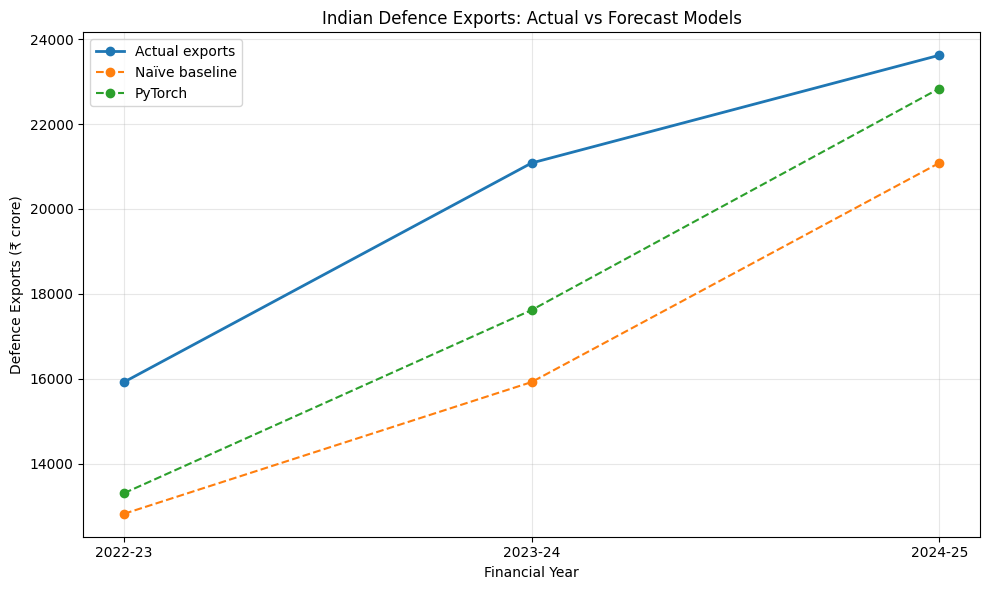

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Test-period visual comparison

years = np.array(test_years)

actual_values = y_test
pytorch_values = test_predictions.detach().cpu().numpy().flatten()

# Naïve predictions:
# each test-year prediction is the immediately preceding actual value
naive_values = np.array([
    12815,  # prediction for 2022-23
    15920,  # prediction for 2023-24
    21083   # prediction for 2024-25
], dtype=float)

plt.figure(figsize=(10, 6))

plt.plot(
    years,
    actual_values,
    marker="o",
    linewidth=2,
    label="Actual exports"
)

plt.plot(
    years,
    naive_values,
    marker="o",
    linestyle="--",
    label="Naïve baseline"
)

plt.plot(
    years,
    pytorch_values,
    marker="o",
    linestyle="--",
    label="PyTorch"
)

plt.title("Indian Defence Exports: Actual vs Forecast Models")
plt.xlabel("Financial Year")
plt.ylabel("Defence Exports (₹ crore)")
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Diagnose the direction and size of PyTorch forecast errors

actual = y_test_tensor.detach().cpu().numpy().flatten()
predicted = test_predictions.detach().cpu().numpy().flatten()

signed_error = actual - predicted
absolute_error = np.abs(signed_error)
percentage_error = (absolute_error / actual) * 100

print("PYTORCH ERROR DIAGNOSTICS")
print("=" * 60)

for i in range(len(test_years)):
    print(
        f"{test_years[i]} | "
        f"Actual: ₹{actual[i]:,.2f} cr | "
        f"Predicted: ₹{predicted[i]:,.2f} cr | "
        f"Signed error: ₹{signed_error[i]:,.2f} cr | "
        f"Absolute % error: {percentage_error[i]:.2f}%"
    )

print("\nSUMMARY")
print("Mean signed error:   ", f"₹{signed_error.mean():,.2f} crore")
print("Mean absolute error: ", f"₹{absolute_error.mean():,.2f} crore")
print("Mean % error (MAPE):  ", f"{percentage_error.mean():.2f}%")

PYTORCH ERROR DIAGNOSTICS
2022-23 | Actual: ₹15,920.00 cr | Predicted: ₹13,301.23 cr | Signed error: ₹2,618.77 cr | Absolute % error: 16.45%
2023-24 | Actual: ₹21,083.00 cr | Predicted: ₹17,617.31 cr | Signed error: ₹3,465.69 cr | Absolute % error: 16.44%
2024-25 | Actual: ₹23,622.00 cr | Predicted: ₹22,838.42 cr | Signed error: ₹783.58 cr | Absolute % error: 3.32%

SUMMARY
Mean signed error:    ₹2,289.35 crore
Mean absolute error:  ₹2,289.35 crore
Mean % error (MAPE):   12.07%


In [ ]:
# Check how well the trained model fits the training data

model.eval()

with torch.no_grad():
    train_predictions = model(X_tensor)

train_actual = y_tensor

train_mse = loss_fn(train_predictions, train_actual).item()
train_mae = torch.mean(
    torch.abs(train_predictions - train_actual)
).item()
train_rmse = train_mse ** 0.5

print("TRAINING-SET DIAGNOSTICS")
print("=" * 60)

for i in range(len(y_train)):
    actual = train_actual[i].item()
    predicted = train_predictions[i].item()
    error = actual - predicted

    print(
        f"Training window {i+1} | "
        f"Actual: ₹{actual:,.2f} cr | "
        f"Predicted: ₹{predicted:,.2f} cr | "
        f"Error: ₹{error:,.2f} cr"
    )

print("\nTRAINING METRICS")
print("MAE: ", f"₹{train_mae:,.2f} crore")
print("RMSE:", f"₹{train_rmse:,.2f} crore")

TRAINING-SET DIAGNOSTICS
Training window 1 | Actual: ₹10,746.00 cr | Predicted: ₹4,068.71 cr | Error: ₹6,677.29 cr
Training window 2 | Actual: ₹9,116.00 cr | Predicted: ₹9,991.96 cr | Error: ₹-875.96 cr
Training window 3 | Actual: ₹8,435.00 cr | Predicted: ₹11,683.64 cr | Error: ₹-3,248.64 cr
Training window 4 | Actual: ₹12,815.00 cr | Predicted: ₹10,423.70 cr | Error: ₹2,391.30 cr

TRAINING METRICS
MAE:  ₹3,298.30 crore
RMSE: ₹3,925.09 crore


In [ ]:
# Normalize the training data
# IMPORTANT: scaling statistics come ONLY from the training period

train_mean = X_train.mean()
train_std = X_train.std()

target_mean = y_train.mean()
target_std = y_train.std()

X_train_scaled = (X_train - train_mean) / train_std
y_train_scaled = (y_train - target_mean) / target_std

X_scaled_tensor = torch.tensor(
    X_train_scaled,
    dtype=torch.float32
)

y_scaled_tensor = torch.tensor(
    y_train_scaled,
    dtype=torch.float32
).reshape(-1, 1)

print("NORMALIZATION PARAMETERS")
print("=" * 60)

print("Input mean:       ", f"{train_mean:,.2f}")
print("Input std:        ", f"{train_std:,.2f}")
print("Target mean:      ", f"{target_mean:,.2f}")
print("Target std:       ", f"{target_std:,.2f}")

print("\nSCALED DATA")
print("=" * 60)

print("X_scaled shape:", X_scaled_tensor.shape)
print("y_scaled shape:", y_scaled_tensor.shape)

print("\nFirst training window:")
print("Original X:", X_train[0])
print("Scaled X:  ", X_train_scaled[0])

print("\nFirst target:")
print("Original y:", y_train[0])
print("Scaled y:  ", y_train_scaled[0])

NORMALIZATION PARAMETERS
Input mean:        7,380.62
Input std:         3,135.98
Target mean:       10,278.00
Target std:        1,688.36

SCALED DATA
X_scaled shape: torch.Size([4, 2])
y_scaled shape: torch.Size([4, 1])

First training window:
Original X: [1522. 4682.]
Scaled X:   [-1.8681968 -0.8605368]

First target:
Original y: 10746.0
Scaled y:   0.2771915


In [ ]:
# Rebuild the same neural network for normalized data

torch.manual_seed(SEED)

scaled_model = ExportForecastNet()

scaled_loss_fn = nn.MSELoss()

scaled_optimizer = torch.optim.Adam(
    scaled_model.parameters(),
    lr=0.001
)

print("NORMALIZED MODEL")
print("=" * 60)
print(scaled_model)

print("\nParameters:", sum(p.numel() for p in scaled_model.parameters()))
print("Loss:", scaled_loss_fn)
print("Optimizer:", scaled_optimizer.__class__.__name__)
print("Learning rate:", scaled_optimizer.param_groups[0]["lr"])

NORMALIZED MODEL
ExportForecastNet(
  (network): Sequential(
    (0): Linear(in_features=2, out_features=8, bias=True)
    (1): ReLU()
    (2): Linear(in_features=8, out_features=1, bias=True)
  )
)

Parameters: 33
Loss: MSELoss()
Optimizer: Adam
Learning rate: 0.001


In [ ]:
# Train the normalized model

EPOCHS = 1000
scaled_loss_history = []

for epoch in range(EPOCHS):

    # Forward pass
    predictions = scaled_model(X_scaled_tensor)

    # Calculate loss
    loss = scaled_loss_fn(predictions, y_scaled_tensor)

    # Clear old gradients
    scaled_optimizer.zero_grad()

    # Backpropagation
    loss.backward()

    # Update parameters
    scaled_optimizer.step()

    # Record loss
    scaled_loss_history.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1:4d} | "
            f"Loss: {loss.item():.6f}"
        )

print("\nNORMALIZED TRAINING COMPLETE")
print("Initial loss:", f"{scaled_loss_history[0]:.6f}")
print("Final loss:  ", f"{scaled_loss_history[-1]:.6f}")

Epoch  100 | Loss: 0.802860
Epoch  200 | Loss: 0.703248
Epoch  300 | Loss: 0.605110
Epoch  400 | Loss: 0.501135
Epoch  500 | Loss: 0.394434
Epoch  600 | Loss: 0.292389
Epoch  700 | Loss: 0.205801
Epoch  800 | Loss: 0.139364
Epoch  900 | Loss: 0.091901
Epoch 1000 | Loss: 0.058549

NORMALIZED TRAINING COMPLETE
Initial loss: 0.988593
Final loss:   0.058549


In [ ]:
# Check the normalized model's fit on the training data
# Predictions are converted back to ₹ crore for interpretation.

scaled_model.eval()

with torch.no_grad():
    train_scaled_predictions = scaled_model(X_scaled_tensor)

# Convert predictions back to original ₹ crore scale
train_predictions_original = (
    train_scaled_predictions.numpy().flatten() * target_std
    + target_mean
)

train_actual_original = y_train.astype(float)

train_errors = train_actual_original - train_predictions_original

train_mae_scaled_model = np.mean(np.abs(train_errors))
train_rmse_scaled_model = np.sqrt(np.mean(train_errors ** 2))

print("NORMALIZED MODEL — TRAINING FIT")
print("=" * 60)

for i in range(len(y_train)):
    print(
        f"Window {i+1} | "
        f"Actual: ₹{train_actual_original[i]:,.2f} cr | "
        f"Predicted: ₹{train_predictions_original[i]:,.2f} cr | "
        f"Error: ₹{train_errors[i]:,.2f} cr"
    )

print("\nTRAINING METRICS")
print("MAE: ", f"₹{train_mae_scaled_model:,.2f} crore")
print("RMSE:", f"₹{train_rmse_scaled_model:,.2f} crore")

NORMALIZED MODEL — TRAINING FIT
Window 1 | Actual: ₹10,746.00 cr | Predicted: ₹10,753.94 cr | Error: ₹-7.94 cr
Window 2 | Actual: ₹9,116.00 cr | Predicted: ₹9,132.91 cr | Error: ₹-16.91 cr
Window 3 | Actual: ₹8,435.00 cr | Predicted: ₹8,729.56 cr | Error: ₹-294.56 cr
Window 4 | Actual: ₹12,815.00 cr | Predicted: ₹12,055.05 cr | Error: ₹759.95 cr

TRAINING METRICS
MAE:  ₹269.84 crore
RMSE: ₹407.62 crore


In [ ]:
# Evaluate the normalized model on the held-out test period

# 1. Scale test inputs using TRAINING statistics only
X_test_scaled = (X_test - train_mean) / train_std

X_test_scaled_tensor = torch.tensor(
    X_test_scaled,
    dtype=torch.float32
)

# 2. Predict in standardized units
scaled_model.eval()

with torch.no_grad():
    test_scaled_predictions = scaled_model(X_test_scaled_tensor)

# 3. Convert predictions back to ₹ crore
test_predictions_scaled_model = (
    test_scaled_predictions.numpy().flatten() * target_std
    + target_mean
)

test_actual_original = y_test.astype(float)

# 4. Calculate errors
scaled_model_errors = (
    test_actual_original - test_predictions_scaled_model
)

scaled_model_mae = np.mean(
    np.abs(scaled_model_errors)
)

scaled_model_rmse = np.sqrt(
    np.mean(scaled_model_errors ** 2)
)

print("NORMALIZED PYTORCH — TEST RESULTS")
print("=" * 60)

for i in range(len(test_years)):
    print(
        f"{test_years[i]} | "
        f"Actual: ₹{test_actual_original[i]:,.2f} cr | "
        f"Predicted: ₹{test_predictions_scaled_model[i]:,.2f} cr | "
        f"Error: ₹{scaled_model_errors[i]:,.2f} cr"
    )

print("\nTEST METRICS")
print("MAE: ", f"₹{scaled_model_mae:,.2f} crore")
print("RMSE:", f"₹{scaled_model_rmse:,.2f} crore")

NORMALIZED PYTORCH — TEST RESULTS
2022-23 | Actual: ₹15,920.00 cr | Predicted: ₹6,872.56 cr | Error: ₹9,047.44 cr
2023-24 | Actual: ₹21,083.00 cr | Predicted: ₹-2,975.21 cr | Error: ₹24,058.21 cr
2024-25 | Actual: ₹23,622.00 cr | Predicted: ₹-14,049.33 cr | Error: ₹37,671.33 cr

TEST METRICS
MAE:  ₹23,592.33 crore
RMSE: ₹26,329.85 crore


In [ ]:
# DIAGNOSTIC: inspect normalized model predictions before inverse transformation

scaled_model.eval()

with torch.no_grad():
    train_scaled_pred = scaled_model(X_scaled_tensor).numpy().flatten()
    test_scaled_pred = scaled_model(X_test_scaled_tensor).numpy().flatten()

# Get actual training targets in standardized units
y_train_scaled_actual = (
    (y_train.astype(float) - target_mean) / target_std
)

# Get actual test targets in standardized units
y_test_scaled_actual = (
    (y_test.astype(float) - target_mean) / target_std
)

print("TRAINING — STANDARDIZED SCALE")
print("=" * 60)

for i in range(len(train_scaled_pred)):
    print(
        f"Actual scaled: {y_train_scaled_actual[i]: .4f} | "
        f"Predicted scaled: {train_scaled_pred[i]: .4f}"
    )

print("\nTEST — STANDARDIZED SCALE")
print("=" * 60)

for i in range(len(test_scaled_pred)):
    print(
        f"{test_years[i]} | "
        f"Actual scaled: {y_test_scaled_actual[i]: .4f} | "
        f"Predicted scaled: {test_scaled_pred[i]: .4f}"
    )

TRAINING — STANDARDIZED SCALE
Actual scaled:  0.2772 | Predicted scaled:  0.2819
Actual scaled: -0.6882 | Predicted scaled: -0.6782
Actual scaled: -1.0916 | Predicted scaled: -0.9171
Actual scaled:  1.5026 | Predicted scaled:  1.0525

TEST — STANDARDIZED SCALE
2022-23 | Actual scaled:  3.3417 | Predicted scaled: -2.0170
2023-24 | Actual scaled:  6.3997 | Predicted scaled: -7.8497
2024-25 | Actual scaled:  7.9035 | Predicted scaled: -14.4088


In [ ]:
# LINEAR PYTORCH MODEL
# 2 inputs -> 1 output
# No hidden layer, no ReLU

import torch.nn as nn

torch.manual_seed(SEED)

class LinearExportForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(2, 1)

    def forward(self, x):
        return self.linear(x)

linear_model = LinearExportForecast()

print("MODEL")
print("=" * 50)
print(linear_model)

print("\nPARAMETERS")
print("=" * 50)

total_params = 0

for name, param in linear_model.named_parameters():
    print(name, param.shape)
    total_params += param.numel()

print("\nTotal trainable parameters:", total_params)

MODEL
LinearExportForecast(
  (linear): Linear(in_features=2, out_features=1, bias=True)
)

PARAMETERS
linear.weight torch.Size([1, 2])
linear.bias torch.Size([1])

Total trainable parameters: 3


In [ ]:
# TRAIN THE LINEAR PYTORCH MODEL

linear_loss_fn = nn.MSELoss()

linear_optimizer = torch.optim.Adam(
    linear_model.parameters(),
    lr=0.001
)

EPOCHS = 1000
linear_losses = []

for epoch in range(EPOCHS):

    # Forward pass
    predictions = linear_model(X_scaled_tensor)

    # Calculate loss
    loss = linear_loss_fn(
        predictions,
        y_scaled_tensor
    )

    # Clear old gradients
    linear_optimizer.zero_grad()

    # Calculate gradients
    loss.backward()

    # Update model parameters
    linear_optimizer.step()

    linear_losses.append(loss.item())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1:4d} | "
            f"Loss: {loss.item():.6f}"
        )

print("\nTRAINING COMPLETE")
print("Initial loss:", f"{linear_losses[0]:.6f}")
print("Final loss:  ", f"{linear_losses[-1]:.6f}")

Epoch  100 | Loss: 1.906054
Epoch  200 | Loss: 1.636954
Epoch  300 | Loss: 1.432773
Epoch  400 | Loss: 1.279563
Epoch  500 | Loss: 1.166875
Epoch  600 | Loss: 1.085483
Epoch  700 | Loss: 1.027330
Epoch  800 | Loss: 0.985724
Epoch  900 | Loss: 0.955434
Epoch 1000 | Loss: 0.932637

TRAINING COMPLETE
Initial loss: 2.257675
Final loss:   0.932637


In [ ]:
# EVALUATE LINEAR PYTORCH MODEL ON THE HELD-OUT TEST SET

linear_model.eval()

with torch.no_grad():
    linear_test_scaled_pred = (
        linear_model(X_test_scaled_tensor)
        .numpy()
        .flatten()
    )

# Convert standardized predictions back to ₹ crore
linear_test_predictions = (
    linear_test_scaled_pred * target_std
    + target_mean
)

# Actual test values
linear_test_actual = y_test.astype(float)

# Errors
linear_test_errors = (
    linear_test_actual - linear_test_predictions
)

linear_test_mae = np.mean(
    np.abs(linear_test_errors)
)

linear_test_rmse = np.sqrt(
    np.mean(linear_test_errors ** 2)
)

print("LINEAR PYTORCH — TEST RESULTS")
print("=" * 60)

for i in range(len(test_years)):
    print(
        f"{test_years[i]} | "
        f"Actual: ₹{linear_test_actual[i]:,.2f} cr | "
        f"Predicted: ₹{linear_test_predictions[i]:,.2f} cr | "
        f"Error: ₹{linear_test_errors[i]:,.2f} cr"
    )

print("\nTEST METRICS")
print("=" * 60)
print(f"MAE:  ₹{linear_test_mae:,.2f} crore")
print(f"RMSE: ₹{linear_test_rmse:,.2f} crore")

LINEAR PYTORCH — TEST RESULTS
2022-23 | Actual: ₹15,920.00 cr | Predicted: ₹9,929.40 cr | Error: ₹5,990.60 cr
2023-24 | Actual: ₹21,083.00 cr | Predicted: ₹9,724.53 cr | Error: ₹11,358.47 cr
2024-25 | Actual: ₹23,622.00 cr | Predicted: ₹9,345.78 cr | Error: ₹14,276.22 cr

TEST METRICS
MAE:  ₹10,541.76 crore
RMSE: ₹11,086.21 crore


In [ ]:
# FINAL ONE-STEP-AHEAD FORECAST
# Forecast FY2025-26 using the RAW NONLINEAR PYTORCH MODEL

# The two most recent observed annual export values are:
# FY2023-24 = ₹21,083 crore
# FY2024-25 = ₹23,622 crore

forecast_input = np.array([
    [21083.0, 23622.0]
], dtype=np.float32)

forecast_input_tensor = torch.tensor(
    forecast_input,
    dtype=torch.float32
)

# Put model into evaluation mode
model.eval()

# Generate forecast without calculating gradients
with torch.no_grad():
    forecast_2025_26 = model(
        forecast_input_tensor
    ).numpy().flatten()[0]

print("FY2025-26 EXPERIMENTAL FORECAST")
print("=" * 60)

print("Input:")
print("FY2023-24 exports: ₹21,083.00 crore")
print("FY2024-25 exports: ₹23,622.00 crore")

print("\nModel forecast:")
print(f"FY2025-26: ₹{forecast_2025_26:,.2f} crore")

print("\nIMPORTANT")
print("This is an experimental one-step-ahead model forecast.")
print("It is NOT a verified official projection.")

FY2025-26 EXPERIMENTAL FORECAST
Input:
FY2023-24 exports: ₹21,083.00 crore
FY2024-25 exports: ₹23,622.00 crore

Model forecast:
FY2025-26: ₹27,107.97 crore

IMPORTANT
This is an experimental one-step-ahead model forecast.
It is NOT a verified official projection.


FINAL ML COMPARISON
     FY  Actual  Naive Baseline  Raw PyTorch  Normalized PyTorch  Linear PyTorch
2022-23 15920.0         15920.0 13301.232422         6872.555664     9929.403320
2023-24 21083.0         21083.0 17617.314453        -2975.210938     9724.529297
2024-25 23622.0         23622.0 22838.416016       -14049.332031     9345.783203

METRICS COMPARISON
                       Model  Test MAE (₹ crore)  Test RMSE (₹ crore)
              Naive Baseline         3602.330000          3774.660000
       Raw Nonlinear PyTorch         2289.350000          2548.390000
Normalized Nonlinear PyTorch        23592.329102         26329.850104
              Linear PyTorch        10541.761393         11086.214733

FY2025-26 EXPERIMENTAL FORECAST
Raw PyTorch forecast: ₹27,107.97 crore


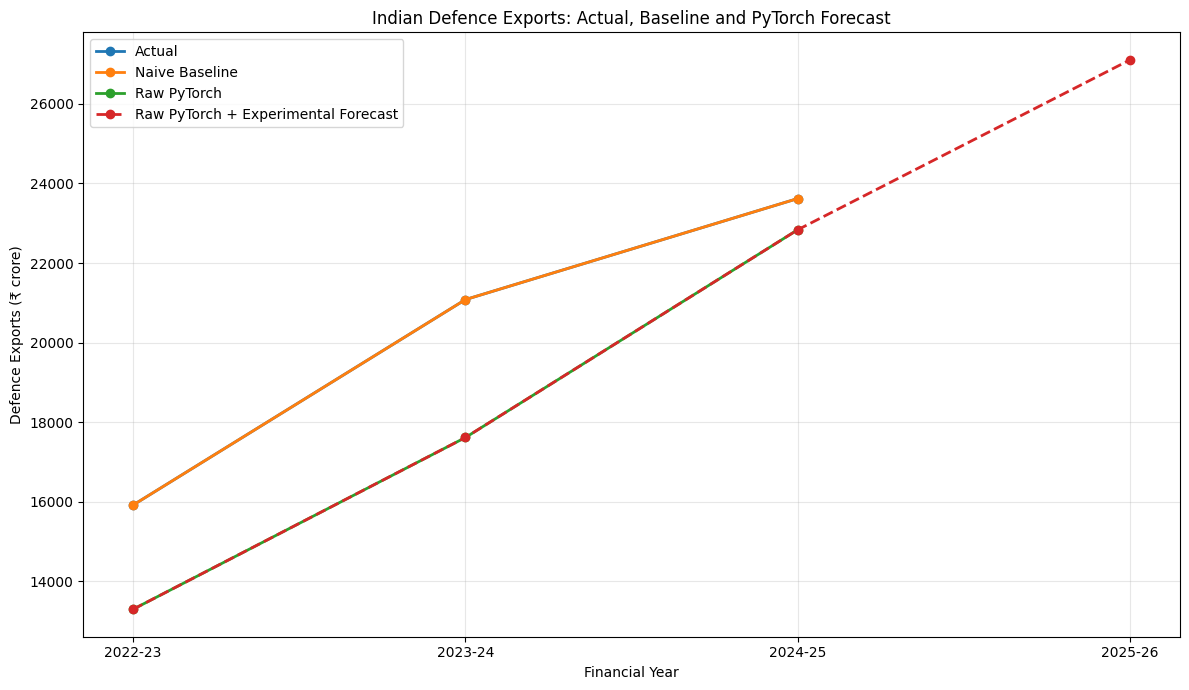

In [ ]:
# FINAL ML RESULTS TABLE + VISUALIZATION
# Corrected for (3,1) prediction arrays

import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. Flatten all prediction arrays
# ---------------------------------------------------------

actual_final = np.asarray(test_actual_original).flatten()
naive_final = np.asarray(y_test).flatten()
raw_pytorch_final = np.asarray(test_predictions).flatten()
normalized_pytorch_final = np.asarray(
    test_predictions_scaled_model
).flatten()
linear_pytorch_final = np.asarray(
    linear_test_predictions
).flatten()

# ---------------------------------------------------------
# 2. Assemble held-out test results
# ---------------------------------------------------------

results_df = pd.DataFrame({
    "FY": list(test_years),
    "Actual": actual_final,
    "Naive Baseline": naive_final,
    "Raw PyTorch": raw_pytorch_final,
    "Normalized PyTorch": normalized_pytorch_final,
    "Linear PyTorch": linear_pytorch_final
})

print("FINAL ML COMPARISON")
print("=" * 80)
print(results_df.to_string(index=False))

# ---------------------------------------------------------
# 3. Metrics comparison
# ---------------------------------------------------------

metrics_df = pd.DataFrame({
    "Model": [
        "Naive Baseline",
        "Raw Nonlinear PyTorch",
        "Normalized Nonlinear PyTorch",
        "Linear PyTorch"
    ],
    "Test MAE (₹ crore)": [
        3602.33,
        2289.35,
        scaled_model_mae,
        linear_test_mae
    ],
    "Test RMSE (₹ crore)": [
        3774.66,
        2548.39,
        scaled_model_rmse,
        linear_test_rmse
    ]
})

print("\nMETRICS COMPARISON")
print("=" * 80)
print(metrics_df.to_string(index=False))

# ---------------------------------------------------------
# 4. FY2025-26 experimental forecast
# ---------------------------------------------------------

print("\nFY2025-26 EXPERIMENTAL FORECAST")
print("=" * 80)
print(f"Raw PyTorch forecast: ₹{forecast_2025_26:,.2f} crore")

# ---------------------------------------------------------
# 5. Final visualization
# ---------------------------------------------------------

plt.figure(figsize=(12, 7))

plt.plot(
    test_years,
    actual_final,
    marker="o",
    linewidth=2,
    label="Actual"
)

plt.plot(
    test_years,
    naive_final,
    marker="o",
    linewidth=2,
    label="Naive Baseline"
)

plt.plot(
    test_years,
    raw_pytorch_final,
    marker="o",
    linewidth=2,
    label="Raw PyTorch"
)

# Connect final observed PyTorch prediction
# to the FY2025-26 experimental forecast
forecast_years = list(test_years) + ["2025-26"]
forecast_values = list(raw_pytorch_final) + [
    float(forecast_2025_26)
]

plt.plot(
    forecast_years,
    forecast_values,
    marker="o",
    linestyle="--",
    linewidth=2,
    label="Raw PyTorch + Experimental Forecast"
)

plt.title(
    "Indian Defence Exports: Actual, Baseline and PyTorch Forecast"
)

plt.xlabel("Financial Year")
plt.ylabel("Defence Exports (₹ crore)")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

In [ ]:
# SAVE FINAL ML ARTIFACTS
# Final forecasting model = RAW NONLINEAR PYTORCH MODEL

import json
import pandas as pd

# ---------------------------------------------------------
# 1. Save the trained PyTorch model weights
# ---------------------------------------------------------

model_path = "/content/defence_exports_pytorch_model.pth"

torch.save(
    model.state_dict(),
    model_path
)

# ---------------------------------------------------------
# 2. Save the final ML comparison table
# ---------------------------------------------------------

results_path = "/content/ml_results.csv"

results_df.to_csv(
    results_path,
    index=False
)

# ---------------------------------------------------------
# 3. Save forecast + methodology metadata
# ---------------------------------------------------------

metadata = {
    "project": "Boom by Booms",
    "target_variable": "Indian defence exports",
    "unit": "₹ crore",
    "frequency": "Annual financial year",

    "training_period": "FY2016-17 to FY2021-22",
    "test_period": "FY2022-23 to FY2024-25",

    "lookback": 2,
    "random_seed": 42,

    "final_model": {
        "type": "PyTorch feed-forward neural network",
        "architecture": "2 -> 8 -> ReLU -> 1",
        "parameters": 33,
        "loss": "MSELoss",
        "optimizer": "Adam",
        "learning_rate": 0.001,
        "epochs": 1000
    },

    "test_metrics": {
        "naive_mae_crore": 3602.33,
        "naive_rmse_crore": 3774.66,
        "raw_pytorch_mae_crore": 2289.35,
        "raw_pytorch_rmse_crore": 2548.39,
        "normalized_pytorch_mae_crore": float(scaled_model_mae),
        "normalized_pytorch_rmse_crore": float(scaled_model_rmse),
        "linear_pytorch_mae_crore": float(linear_test_mae),
        "linear_pytorch_rmse_crore": float(linear_test_rmse)
    },

    "experimental_forecast": {
        "financial_year": "FY2025-26",
        "forecast_crore": float(forecast_2025_26),
        "status": "Experimental one-step-ahead model forecast",
        "not_official_projection": True
    },

    "limitations": [
        "Only 9 annual observations were available.",
        "Chronological training set produced only 4 supervised windows.",
        "Held-out test set contains only 3 annual observations.",
        "Neural-network generalization is therefore highly uncertain.",
        "Forecast should not be interpreted as an official government projection."
    ]
}

metadata_path = "/content/ml_forecast_metadata.json"

with open(metadata_path, "w") as f:
    json.dump(
        metadata,
        f,
        indent=4
    )

# ---------------------------------------------------------
# 4. Confirm files
# ---------------------------------------------------------

print("ML ARTIFACTS SAVED")
print("=" * 60)

print(f"Model:    {model_path}")
print(f"Results:  {results_path}")
print(f"Metadata: {metadata_path}")

print("\nFY2025-26 experimental forecast:")
print(f"₹{forecast_2025_26:,.2f} crore")

ML ARTIFACTS SAVED
Model:    /content/defence_exports_pytorch_model.pth
Results:  /content/ml_results.csv
Metadata: /content/ml_forecast_metadata.json

FY2025-26 experimental forecast:
₹27,107.97 crore


In [ ]:
# REPRODUCIBILITY CHECK
# Load the saved model into a fresh model instance
# and verify that it reproduces the same FY2025-26 forecast.

# ---------------------------------------------------------
# 1. Create a completely fresh model
# ---------------------------------------------------------

reloaded_model = ExportForecastNet()

# ---------------------------------------------------------
# 2. Load saved parameters
# ---------------------------------------------------------

reloaded_model.load_state_dict(
    torch.load(
        model_path,
        weights_only=True,
        map_location="cpu"
    )
)

# ---------------------------------------------------------
# 3. Put model into inference mode
# ---------------------------------------------------------

reloaded_model.eval()

# ---------------------------------------------------------
# 4. Recreate the FY2025-26 input
# ---------------------------------------------------------

verification_input = torch.tensor(
    [[21083.0, 23622.0]],
    dtype=torch.float32
)

# ---------------------------------------------------------
# 5. Generate forecast
# ---------------------------------------------------------

with torch.no_grad():
    reloaded_forecast = (
        reloaded_model(verification_input)
        .numpy()
        .flatten()[0]
    )

# ---------------------------------------------------------
# 6. Compare with original forecast
# ---------------------------------------------------------

difference = abs(
    forecast_2025_26 - reloaded_forecast
)

print("MODEL REPRODUCIBILITY CHECK")
print("=" * 60)

print(
    f"Original forecast:  ₹{forecast_2025_26:,.6f} crore"
)

print(
    f"Reloaded forecast:  ₹{reloaded_forecast:,.6f} crore"
)

print(
    f"Absolute difference: ₹{difference:,.10f} crore"
)

print("\nSTATUS")

if difference < 0.0001:
    print("PASS — Saved model reproduces the original forecast.")
else:
    print("FAIL — Reloaded model does not reproduce the forecast.")

MODEL REPRODUCIBILITY CHECK
Original forecast:  ₹27,107.970703 crore
Reloaded forecast:  ₹27,107.970703 crore
Absolute difference: ₹0.0000000000 crore

STATUS
PASS — Saved model reproduces the original forecast.


In [ ]:
import shutil
import subprocess

docker_path = shutil.which("docker")

if docker_path is None:
    print("DOCKER NOT AVAILABLE IN THIS COLAB RUNTIME")
else:
    print("Docker executable found:")
    print(docker_path)

    result = subprocess.run(
        ["docker", "--version"],
        capture_output=True,
        text=True
    )

    print(result.stdout)

DOCKER NOT AVAILABLE IN THIS COLAB RUNTIME


In [ ]:
# CREATE DOCKER DEPLOYMENT PACKAGE

import os
import shutil

docker_dir = "/content/boom_by_booms_ml"

os.makedirs(docker_dir, exist_ok=True)

# ---------------------------------------------------------
# 1. Copy trained model
# ---------------------------------------------------------

shutil.copy(
    model_path,
    os.path.join(
        docker_dir,
        "model.pth"
    )
)

# ---------------------------------------------------------
# 2. Create inference script
# ---------------------------------------------------------

inference_code = r'''
import torch
import torch.nn as nn


class ExportForecastNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(2, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.network(x)


# Load model
model = ExportForecastNet()

model.load_state_dict(
    torch.load(
        "model.pth",
        weights_only=True,
        map_location="cpu"
    )
)

model.eval()

# Latest two observed annual export values
# FY2023-24 = ₹21,083 crore
# FY2024-25 = ₹23,622 crore

input_data = torch.tensor(
    [[21083.0, 23622.0]],
    dtype=torch.float32
)

with torch.no_grad():
    forecast = model(
        input_data
    ).item()

print("=" * 60)
print("BOOM BY BOOMS — DEFENCE EXPORT FORECAST")
print("=" * 60)
print()
print("Input:")
print("FY2023-24: ₹21,083.00 crore")
print("FY2024-25: ₹23,622.00 crore")
print()
print("Experimental FY2025-26 forecast:")
print(f"₹{forecast:,.2f} crore")
print()
print("Model: PyTorch feed-forward neural network")
print("Architecture: 2 -> 8 -> ReLU -> 1")
print("Status: Experimental model forecast")
print("=" * 60)
'''

with open(
    os.path.join(docker_dir, "inference.py"),
    "w"
) as f:
    f.write(inference_code)

# ---------------------------------------------------------
# 3. Create requirements.txt
# ---------------------------------------------------------

requirements = """torch==2.11.0
"""

with open(
    os.path.join(docker_dir, "requirements.txt"),
    "w"
) as f:
    f.write(requirements)

# ---------------------------------------------------------
# 4. Create Dockerfile
# ---------------------------------------------------------

dockerfile = """FROM python:3.12-slim

WORKDIR /app

COPY requirements.txt .

RUN pip install --no-cache-dir -r requirements.txt

COPY model.pth .
COPY inference.py .

CMD ["python", "inference.py"]
"""

with open(
    os.path.join(docker_dir, "Dockerfile"),
    "w"
) as f:
    f.write(dockerfile)

# ---------------------------------------------------------
# 5. Create README
# ---------------------------------------------------------

readme = """# Boom by Booms — ML Forecast

Experimental PyTorch forecasting component for the
Boom by Booms research project.

## Model

Architecture:
2 -> 8 -> ReLU -> 1

Target:
Indian defence exports (₹ crore)

Training period:
FY2016-17 to FY2021-22

Held-out test period:
FY2022-23 to FY2024-25

Experimental forecast:
FY2025-26

## Run locally with Docker

Build:

docker build -t boom-by-booms-ml .

Run:

docker run --rm boom-by-booms-ml

Expected forecast:

Approximately ₹27,107.97 crore

This is an experimental model forecast and
not an official government projection.
"""

with open(
    os.path.join(docker_dir, "README.md"),
    "w"
) as f:
    f.write(readme)

# ---------------------------------------------------------
# 6. Create ZIP package
# ---------------------------------------------------------

zip_path = shutil.make_archive(
    "/content/boom_by_booms_ml",
    "zip",
    docker_dir
)

print("DOCKER PACKAGE CREATED")
print("=" * 60)

print("Folder:")
print(docker_dir)

print("\nZIP:")
print(zip_path)

print("\nContents:")
for filename in sorted(os.listdir(docker_dir)):
    print(" -", filename)

DOCKER PACKAGE CREATED
Folder:
/content/boom_by_booms_ml

ZIP:
/content/boom_by_booms_ml.zip

Contents:
 - Dockerfile
 - README.md
 - inference.py
 - model.pth
 - requirements.txt


In [ ]:
from google.colab import files

files.download("/content/boom_by_booms_ml.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>